In [4]:
import pandas as pd
df = pd.read_csv("C:\\Users\\thula\\Downloads\\swiggy_dataset.csv")
print(df.shape)
print(df.head())
print(df.info())

(10000, 12)
   Order_ID  Order_Date Order_Time     City  Restaurant_Name       Cuisine  \
0      1001  2026-03-16   22:31:00   Mumbai      Pizza Point      Japanese   
1      1002  2026-02-28   15:22:00     Pune  Tandoori Nights     Fast Food   
2      1003  2026-03-30   15:09:00  Chennai      Sushi World  South Indian   
3      1004  2026-03-28   17:31:00     Pune      Dosa Palace  South Indian   
4      1005  2026-02-27   11:36:00     Pune      Sushi World      Japanese   

   Customer_Rating  Delivery_Time_Minutes  Order_Value Payment_Method  \
0              4.6                     35       604.15            UPI   
1              3.1                     54       236.73           Card   
2              3.6                     35      1039.67            UPI   
3              4.8                     67       518.40            UPI   
4              3.6                     26      1146.40            COD   

   Discount_Applied Order_Status  
0             28.78    Delivered  
1         

In [5]:
df.describe()

,Order_ID,Customer_Rating,Delivery_Time_Minutes,Order_Value,Discount_Applied
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000
mean,6000.50000,3.741710,44.526100,703.559021,100.941127
std,2886.89568,0.718455,14.411401,289.384575,58.143768
min,1001.00000,2.500000,20.000000,200.090000,0.010000
25%,3500.75000,3.100000,32.000000,453.040000,50.797500
50%,6000.50000,3.700000,45.000000,704.225000,100.215000
75%,8500.25000,4.400000,57.000000,956.817500,152.382500
max,11000.00000,5.000000,69.000000,1199.810000,199.980000


In [6]:
mumbai_orders = df[df["City"] == "Mumbai"]

mumbai_orders.head()

,Order_ID,Order_Date,Order_Time,City,Restaurant_Name,Cuisine,Customer_Rating,Delivery_Time_Minutes,Order_Value,Payment_Method,Discount_Applied,Order_Status
0,1001,2026-03-16,22:31:00,Mumbai,Pizza Point,Japanese,4.6,35,604.15,UPI,28.78,Delivered
10,1011,2026-03-16,10:56:00,Mumbai,Tandoori Nights,South Indian,4.5,39,877.95,UPI,23.56,Delivered
14,1015,2026-03-13,21:13:00,Mumbai,Burger Town,Japanese,2.7,41,810.43,Card,179.00,Delivered
16,1017,2026-03-13,20:29:00,Mumbai,Dosa Palace,Fast Food,3.5,60,718.09,Card,170.17,Delivered
19,1020,2026-03-05,16:55:00,Mumbai,Burger Town,Fast Food,4.3,27,622.39,UPI,127.19,Cancelled


In [7]:
print(len(mumbai_orders))

1975


In [8]:
df["City"].value_counts()

City
Hyderabad    2047
Pune         2019
Bangalore    2016
Mumbai       1975
Chennai      1943
Name: count, dtype: int64

In [9]:
average_delivery = df["Delivery_Time_Minutes"].mean()

print("Average Delivery Time:", round(average_delivery, 2))

Average Delivery Time: 44.53


In [10]:
total_order_value = df["Order_Value"].sum()

print("Total Order Value:", round(total_order_value, 2))

Total Order Value: 7035590.21


In [11]:
#data cleaning and duplicate checking
df.isnull().sum()

Order_ID                 0
Order_Date               0
Order_Time               0
City                     0
Restaurant_Name          0
Cuisine                  0
Customer_Rating          0
Delivery_Time_Minutes    0
Order_Value              0
Payment_Method           0
Discount_Applied         0
Order_Status             0
dtype: int64

In [12]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [13]:
#Convert date and time
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

df["Order_Time"] = pd.to_datetime(
    df["Order_Time"],
    format="%H:%M:%S"
).dt.time

print(df[["Order_Date", "Order_Time"]].dtypes)

Order_Date    datetime64[ns]
Order_Time            object
dtype: object


In [14]:
#Check invalid values
print("Invalid ratings:",
      ((df["Customer_Rating"] < 1) |
       (df["Customer_Rating"] > 5)).sum())

print("Invalid delivery times:",
      (df["Delivery_Time_Minutes"] <= 0).sum())

print("Negative order values:",
      (df["Order_Value"] < 0).sum())

print("Negative discounts:",
      (df["Discount_Applied"] < 0).sum())

Invalid ratings: 0
Invalid delivery times: 0
Negative order values: 0
Negative discounts: 0


In [15]:
#Clean the column names
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df.columns.tolist())

['order_id', 'order_date', 'order_time', 'city', 'restaurant_name', 'cuisine', 'customer_rating', 'delivery_time_minutes', 'order_value', 'payment_method', 'discount_applied', 'order_status']


In [17]:
#Remove duplicates safely
df = df.drop_duplicates()

df = df.drop_duplicates(subset=["order_id"])

print("Remaining records:", len(df))

Remaining records: 10000


In [18]:
#eda
#Total number of orders
total_orders = df["order_id"].count()

print("Total Orders:", total_orders)

Total Orders: 10000


In [19]:
#Total delivered and cancelled orders
df["order_status"].value_counts()

order_status
Delivered    8494
Cancelled    1506
Name: count, dtype: int64

In [20]:
#Calculate delivery percentage
delivery_percentage = (
    (df["order_status"] == "Delivered").sum()
    / len(df)
) * 100

print("Delivery Percentage:", round(delivery_percentage, 2), "%")

Delivery Percentage: 84.94 %


In [21]:
#Calculate cancellation percentage
cancellation_percentage = (
    (df["order_status"] == "Cancelled").sum()
    / len(df)
) * 100

print("Cancellation Percentage:",
      round(cancellation_percentage, 2), "%")

Cancellation Percentage: 15.06 %


In [22]:
#average customer rating
print("Average Rating:",
      round(df["customer_rating"].mean(), 2))

Average Rating: 3.74


In [23]:
#average order value
print("Average Order Value:",
      round(df["order_value"].mean(), 2))

Average Order Value: 703.56


In [24]:
#the most popular city
print(df["city"].value_counts().idxmax())

Hyderabad


In [25]:
#Correlation analysis
numeric_data = df.select_dtypes(include="number")

correlation = numeric_data.corr()

print(correlation.round(2))

                       order_id  customer_rating  delivery_time_minutes  \
order_id                   1.00            -0.01                  -0.01   
customer_rating           -0.01             1.00                   0.02   
delivery_time_minutes     -0.01             0.02                   1.00   
order_value               -0.00            -0.02                  -0.01   
discount_applied           0.01             0.01                   0.02   

                       order_value  discount_applied  
order_id                     -0.00              0.01  
customer_rating              -0.02              0.01  
delivery_time_minutes        -0.01              0.02  
order_value                   1.00              0.01  
discount_applied              0.01              1.00  


In [26]:
#City-wise order analysis
city_orders = df["city"].value_counts()

print(city_orders)

city
Hyderabad    2047
Pune         2019
Bangalore    2016
Mumbai       1975
Chennai      1943
Name: count, dtype: int64


In [27]:
#Restaurant-wise order analysis
restaurant_orders = df["restaurant_name"].value_counts()

print(restaurant_orders)

restaurant_name
Pizza Point        1721
Dosa Palace        1697
Sushi World        1672
Tandoori Nights    1671
Biryani Hub        1627
Burger Town        1612
Name: count, dtype: int64


In [28]:
#Cuisine-wise analysis
cuisine_orders = df["cuisine"].value_counts()

print(cuisine_orders)

cuisine
Japanese        2064
South Indian    2057
Indian          1994
Italian         1951
Fast Food       1934
Name: count, dtype: int64


In [29]:
#Average rating by restaurant
restaurant_rating = (
    df.groupby("restaurant_name")["customer_rating"]
    .mean()
    .sort_values(ascending=False)
)

print(restaurant_rating.round(2))

restaurant_name
Tandoori Nights    3.76
Burger Town        3.76
Biryani Hub        3.75
Pizza Point        3.74
Dosa Palace        3.73
Sushi World        3.71
Name: customer_rating, dtype: float64


In [30]:
#City-wise average order value
city_revenue = (
    df.groupby("city")["order_value"]
    .mean()
    .sort_values(ascending=False)
)

print(city_revenue.round(2))

city
Pune         711.62
Mumbai       709.51
Hyderabad    699.92
Bangalore    699.85
Chennai      696.82
Name: order_value, dtype: float64


In [31]:
#Restaurant and cuisine relationship
restaurant_cuisine = pd.crosstab(
    df["restaurant_name"],
    df["cuisine"]
)

print(restaurant_cuisine)

cuisine          Fast Food  Indian  Italian  Japanese  South Indian
restaurant_name                                                    
Biryani Hub            318     341      309       312           347
Burger Town            328     305      322       337           320
Dosa Palace            350     306      322       354           365
Pizza Point            343     364      336       348           330
Sushi World            291     343      334       359           345
Tandoori Nights        304     335      328       354           350


In [32]:
#Delivery Time and Customer-Rating Analysis
avg_delivery = df["delivery_time_minutes"].mean()

print("Average Delivery Time:",
      round(avg_delivery, 2), "minutes")

Average Delivery Time: 44.53 minutes


In [33]:
#Minimum and maximum delivery time
print("Minimum Delivery:",
      df["delivery_time_minutes"].min())

print("Maximum Delivery:",
      df["delivery_time_minutes"].max())

Minimum Delivery: 20
Maximum Delivery: 69


In [34]:
#delivery-time groups
bins = [0, 30, 40, 50, 60, float("inf")]

labels = [
    "20-30 Minutes",
    "31-40 Minutes",
    "41-50 Minutes",
    "51-60 Minutes",
    "Above 60 Minutes"
]

df["delivery_group"] = pd.cut(
    df["delivery_time_minutes"],
    bins=bins,
    labels=labels
)

delivery_distribution = df["delivery_group"].value_counts().sort_index()

print(delivery_distribution)

delivery_group
20-30 Minutes       2217
31-40 Minutes       1916
41-50 Minutes       2047
51-60 Minutes       2029
Above 60 Minutes    1791
Name: count, dtype: int64


In [35]:
#Customer rating distribution
print(df["customer_rating"].value_counts().sort_index())

customer_rating
2.5    177
2.6    407
2.7    420
2.8    391
2.9    398
3.0    411
3.1    417
3.2    414
3.3    410
3.4    386
3.5    439
3.6    383
3.7    389
3.8    400
3.9    389
4.0    397
4.1    432
4.2    427
4.3    400
4.4    371
4.5    407
4.6    407
4.7    355
4.8    383
4.9    398
5.0    192
Name: count, dtype: int64


In [36]:
#Average rating by city
city_rating = (
    df.groupby("city")["customer_rating"]
    .mean()
    .sort_values(ascending=False)
)

print(city_rating.round(2))

city
Pune         3.75
Hyderabad    3.75
Bangalore    3.74
Chennai      3.73
Mumbai       3.73
Name: customer_rating, dtype: float64


In [37]:
#Average delivery time by city
city_delivery = (
    df.groupby("city")["delivery_time_minutes"]
    .mean()
    .sort_values(ascending=False)
)

print(city_delivery.round(2))

city
Pune         45.05
Hyderabad    44.63
Mumbai       44.48
Chennai      44.24
Bangalore    44.22
Name: delivery_time_minutes, dtype: float64


In [38]:
#Relationship between delivery time and rating
delivery_rating = df[
    ["delivery_time_minutes", "customer_rating"]
].corr()

print(delivery_rating.round(2))

                       delivery_time_minutes  customer_rating
delivery_time_minutes                   1.00             0.02
customer_rating                         0.02             1.00


In [39]:
#Payment method distribution
payment_counts = df["payment_method"].value_counts()

print(payment_counts)

payment_method
Card    3377
UPI     3346
COD     3277
Name: count, dtype: int64


In [40]:
#Calculate payment percentages
payment_percentage = (
    df["payment_method"].value_counts(normalize=True) * 100
)

print(payment_percentage.round(2))

payment_method
Card    33.77
UPI     33.46
COD     32.77
Name: proportion, dtype: float64


In [41]:
#Order status analysis
status_counts = df["order_status"].value_counts()

print(status_counts)

order_status
Delivered    8494
Cancelled    1506
Name: count, dtype: int64


In [42]:
#Cancellation percentage
total = len(df)

cancelled = (df["order_status"] == "Cancelled").sum()

cancel_percentage = (cancelled / total) * 100

print("Cancellation Rate:",
      round(cancel_percentage, 2), "%")

Cancellation Rate: 15.06 %


In [43]:
#Payment method versus order status
payment_status = pd.crosstab(
    df["payment_method"],
    df["order_status"]
)

print(payment_status)

order_status    Cancelled  Delivered
payment_method                      
COD                   510       2767
Card                  496       2881
UPI                   500       2846


In [44]:
#Cancellation rate by payment method
cancellation_by_payment = (
    df.assign(
        is_cancelled=df["order_status"] == "Cancelled"
    )
    .groupby("payment_method")["is_cancelled"]
    .mean() * 100
)

print(cancellation_by_payment.round(2))

payment_method
COD     15.56
Card    14.69
UPI     14.94
Name: is_cancelled, dtype: float64


In [45]:
#City-wise cancellation analysis
city_status = pd.crosstab(
    df["city"],
    df["order_status"]
)

print(city_status)

order_status  Cancelled  Delivered
city                              
Bangalore           293       1723
Chennai             290       1653
Hyderabad           325       1722
Mumbai              286       1689
Pune                312       1707


In [46]:
#Calculate total discounts
total_discount = df["discount_applied"].sum()

print("Total Discount:", round(total_discount, 2))

Total Discount: 1009411.27


In [47]:
#Calculate average order value for delivered orders
delivered_orders = df[
    df["order_status"] == "Delivered"
]

average_delivered_value = delivered_orders["order_value"].mean()

print("Average Delivered Order Value:",
      round(average_delivered_value, 2))

Average Delivered Order Value: 703.89


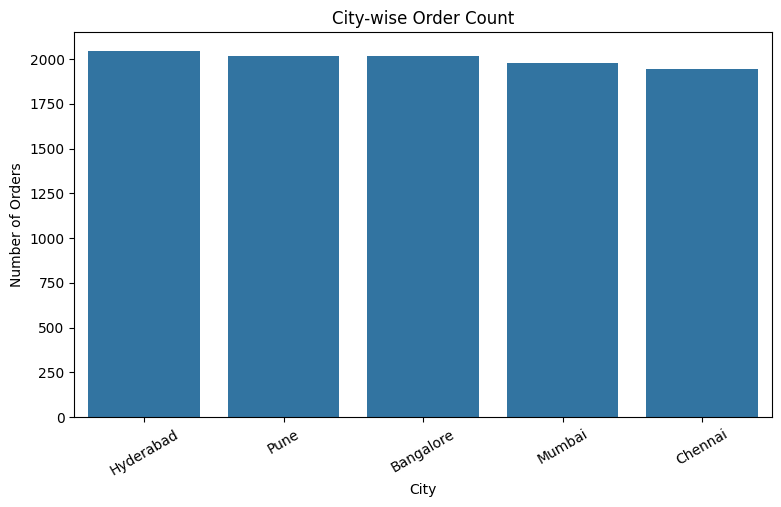

In [51]:
#City-wise Order Count – Bar Chart
#Business question: Which city has the highest number of Swiggy orders?
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="city",
    order=df["city"].value_counts().index
)

plt.title("City-wise Order Count")
plt.xlabel("City")
plt.ylabel("Number of Orders")
plt.xticks(rotation=30)

plt.show()

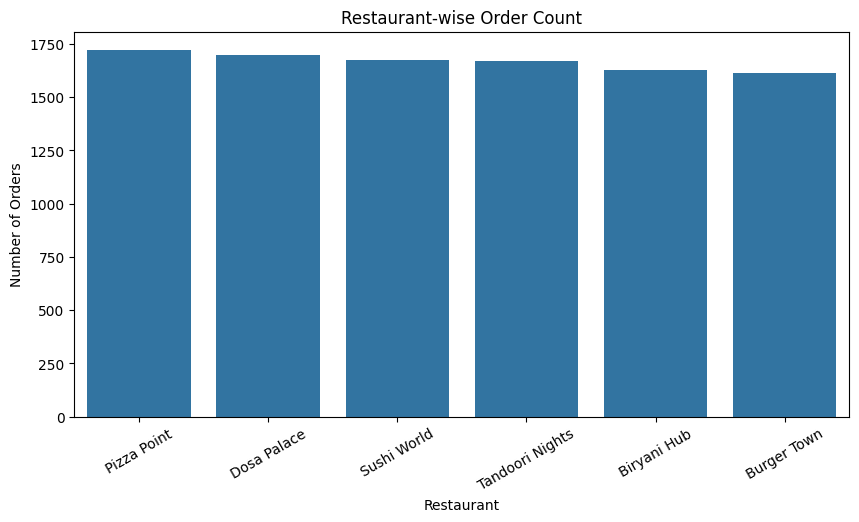

In [52]:
#Restaurant-wise Orders – Bar Chart
plt.figure(figsize=(10, 5))

restaurant_orders = df["restaurant_name"].value_counts()

sns.barplot(
    x=restaurant_orders.index,
    y=restaurant_orders.values
)

plt.title("Restaurant-wise Order Count")
plt.xlabel("Restaurant")
plt.ylabel("Number of Orders")
plt.xticks(rotation=30)

plt.show()

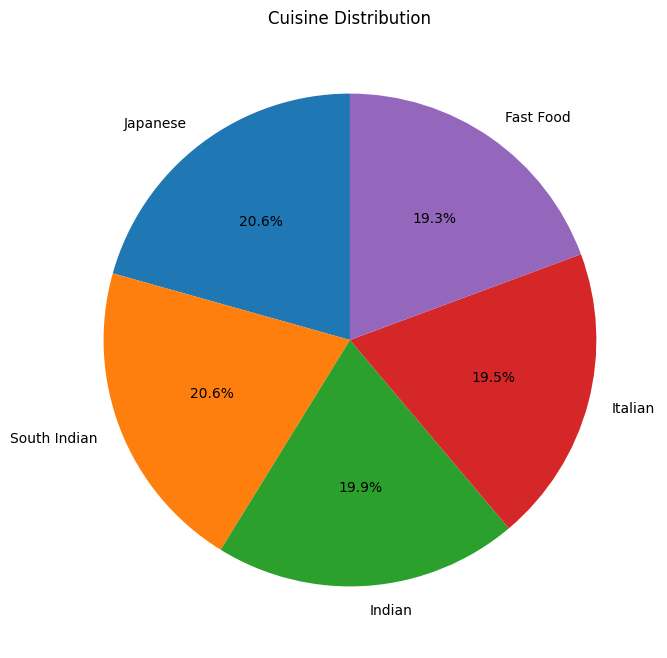

In [53]:
#Cuisine Distribution – Pie Chart
cuisine_counts = df["cuisine"].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    cuisine_counts.values,
    labels=cuisine_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Cuisine Distribution")

plt.show()

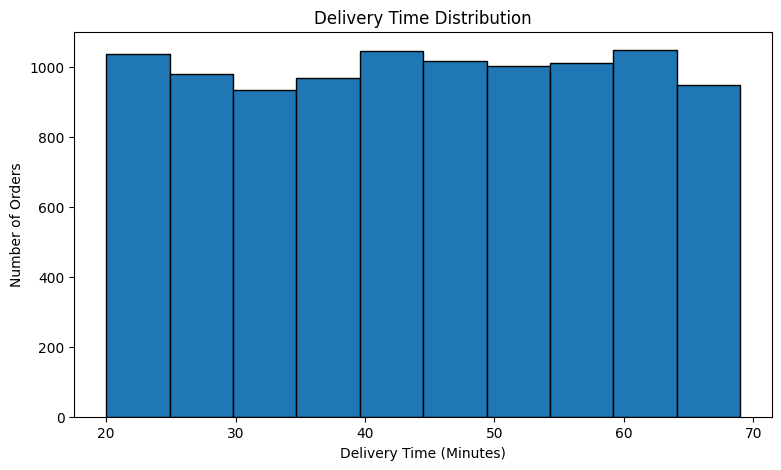

In [55]:
#Delivery Time Distribution – Histogram
#Business question: How long do customers wait for their orders?
plt.figure(figsize=(9, 5))

plt.hist(
    df["delivery_time_minutes"],
    bins=10,
    edgecolor="black"
)

plt.title("Delivery Time Distribution")
plt.xlabel("Delivery Time (Minutes)")
plt.ylabel("Number of Orders")

plt.show()

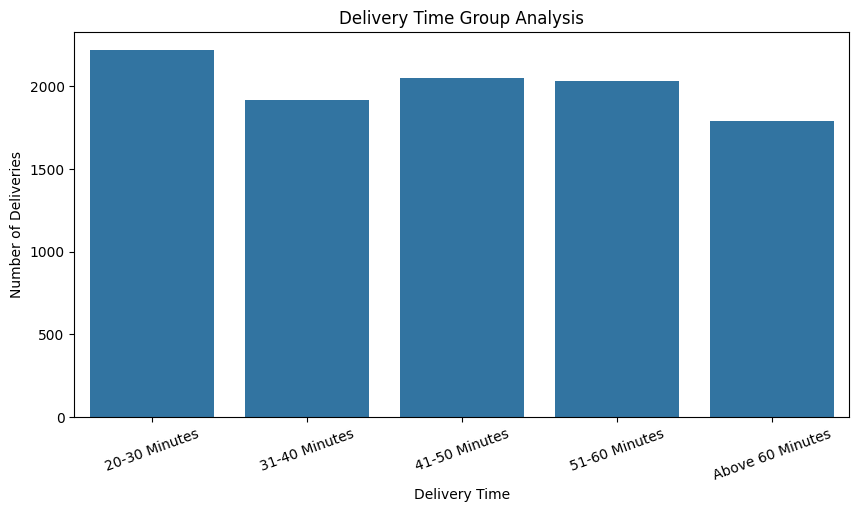

In [56]:
#Delivery Groups – Column Chart
#This uses the five delivery-time groups we created in Topic 5.
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="delivery_group",
    order=labels
)

plt.title("Delivery Time Group Analysis")
plt.xlabel("Delivery Time")
plt.ylabel("Number of Deliveries")
plt.xticks(rotation=20)

plt.show()

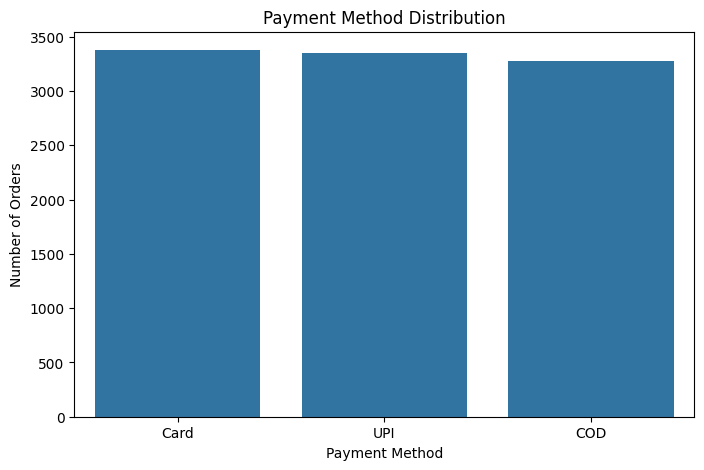

In [57]:
#Payment Method Distribution – Count Plot
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="payment_method",
    order=df["payment_method"].value_counts().index
)

plt.title("Payment Method Distribution")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")

plt.show()

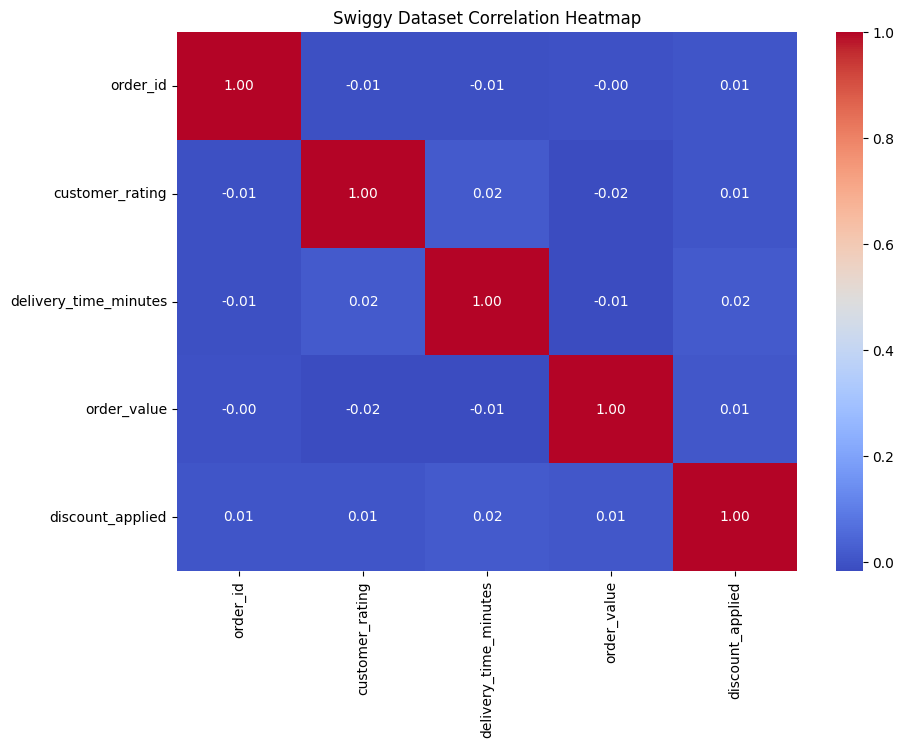

In [58]:
#Correlation Heatmap
plt.figure(figsize=(10, 7))

numeric_df = df.select_dtypes(include="number")

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Swiggy Dataset Correlation Heatmap")

plt.show()